In [1]:
import numpy as np
import matplotlib.pyplot as plt
import f90nml
import dispatch_utils as du
from dusty_box import dusty_box

In [2]:
def read_nml(iout, datadir='../data', verbose=False):
    import os

    snapdir = datadir + '/' + "{:05d}".format(iout)
    files = [f for f in os.listdir(snapdir) if f.endswith('snapshot.nml')]
    for f in files:
        if verbose:
            print('parsing',snapdir)
        nml_list = f90nml.read(snapdir+'/'+f)

    idx_dict = {}
    for k,v in nml_list['idx_nml'].items():
        idx_dict[k] = v

    return nml_list, idx_dict


In [3]:
# turn on interactive plotting
plt.interactive(True)
# set font style and size
plt.rc('text', usetex=True)
plt.rc('font', **{'family':'serif','serif':['Computer Modern Roman']})
plt.rc('figure',figsize = (8.5,7))
plt.rc('font', size = 18)

In [4]:
# parameters
istart = 0
iend = 20
datadir = '../data'

In [9]:
s_nmls = []
first_time = True
vx_dust_values = []
times = []
for i in range(istart,iend+1):
    # read snapshot namelist
    s_nml, idx = read_nml(i,datadir=datadir,verbose=False)
    s_nmls.append(s_nml)
    if first_time:
        ndust = s_nml['force_params']['nc']
        drag_regime = s_nml['force_params']['drag'].strip()
        vx_gas0 = s_nml['experiment_params']['vx']
        vx_dust0 = s_nml['experiment_params']['vx2']
        d_gas0 = s_nml['experiment_params']['rho']
        d_dust0 = s_nml['experiment_params']['rho2']
        Kdrag = s_nml['force_params']['k']
        pindex = s_nml['force_params']['a']
        first_time = False
    snap = du.snapshot(iout=i,data=datadir)
    p0 = snap.patches[0]
    print("ID:",p0.id,"; t =",p0.time)
    times.append(p0.time)
    # determine array index of dust density and x-velocity
    idx_offset = int(s_nml['snapshot_nml']['nv']/ndust)
    idx_d_dust = idx['d'] + idx_offset
    idx_px_dust = idx['px'] + idx_offset
    imid = int((p0.ui[0] + p0.li[0])/2)
    vx_dust = p0.data[:,0,0,idx_px_dust]/p0.data[:,0,0,idx_d_dust]
    print("vx_dust min:",np.min(vx_dust),"max:",np.max(vx_dust))
    vx_dust_values.append(vx_dust[imid])

ID: 1 ; t = 0.0
vx_dust min: 1.0 max: 1.0
ID: 1 ; t = 0.1
vx_dust min: 0.09939105 max: 0.09939105
ID: 1 ; t = 0.2
vx_dust min: 0.056714263 max: 0.056714263
ID: 1 ; t = 0.3
vx_dust min: 0.04158878 max: 0.04158878
ID: 1 ; t = 0.4
vx_dust min: 0.033852767 max: 0.033852767
ID: 1 ; t = 0.5
vx_dust min: 0.029149983 max: 0.029149983
ID: 1 ; t = 0.6
vx_dust min: 0.025990728 max: 0.025990728
ID: 1 ; t = 0.7
vx_dust min: 0.023722252 max: 0.023722252
ID: 1 ; t = 0.8
vx_dust min: 0.022014365 max: 0.022014365
ID: 1 ; t = 0.9
vx_dust min: 0.020682488 max: 0.020682488
ID: 1 ; t = 1.0
vx_dust min: 0.019614203 max: 0.019614203
ID: 1 ; t = 1.1
vx_dust min: 0.018738527 max: 0.018738527
ID: 1 ; t = 1.2
vx_dust min: 0.018007679 max: 0.018007679
ID: 1 ; t = 1.3
vx_dust min: 0.017388582 max: 0.017388582
ID: 1 ; t = 1.4
vx_dust min: 0.016857253 max: 0.016857253
ID: 1 ; t = 1.5
vx_dust min: 0.01639633 max: 0.01639633
ID: 1 ; t = 1.6
vx_dust min: 0.015992695 max: 0.015992695
ID: 1 ; t = 1.7
vx_dust min: 0.01563

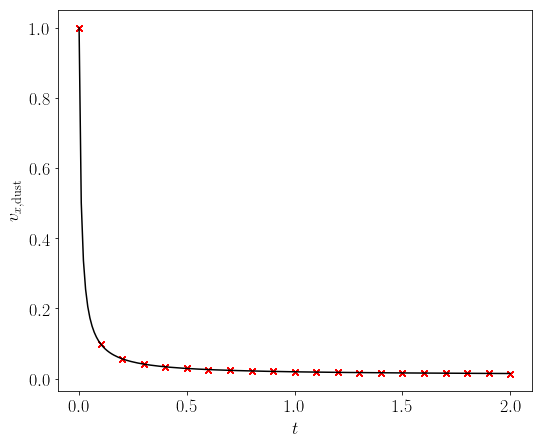

In [8]:
fig = plt.figure(1)
fig.clf()
cax = fig.add_subplot(1,1,1)
for i in range(istart,iend+1):
    plt.plot(times,vx_dust_values,'rx')

plt.xlabel(r"$t$")
plt.ylabel(r"$v_{x, {\rm dust}}$")
qanalytic = dusty_box(drag_regime, 2.0, vx_gas0, vx_dust0, d_gas0, d_dust0, Kdrag, pindex)
plt.plot(qanalytic[0,:],qanalytic[3,:],'k-')